# NewsScope - 02. Text Preprocessing

This notebook builds and evaluates the text preprocessing pipeline for the NewsScope system. It covers:
1. **Lowercase Conversion**
2. **Punctuation & Unwanted Character Removal** (HTML entities, URLs, symbols)
3. **Tokenisation**
4. **Stopword Removal**
5. **Stemming** (PorterStemmer)
6. **Lemmatization** (WordNetLemmatizer)
7. **Compare Original and Processed Text**
8. **Save Processed Datasets** (`train_processed.csv`, `test_processed.csv`)

### Setup & Data Loading
Import required NLP and data manipulation libraries, verify NLTK resources, and load the raw datasets.

In [1]:
import os
import re
import string
import time
from collections import Counter

import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd

# Ensure NLTK resources are available
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

# Determine file paths
raw_dir = (
    os.path.abspath(os.path.join(os.getcwd(), "..", "data", "raw"))
    if os.path.basename(os.getcwd()) == "notebooks"
    else os.path.abspath("data/raw")
)
processed_dir = (
    os.path.abspath(os.path.join(os.getcwd(), "..", "data", "processed"))
    if os.path.basename(os.getcwd()) == "notebooks"
    else os.path.abspath("data/processed")
)
os.makedirs(processed_dir, exist_ok=True)

train_df = pd.read_csv(os.path.join(raw_dir, "train.csv"))
test_df = pd.read_csv(os.path.join(raw_dir, "test.csv"))

# Add category label mapping
label_mapping = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}
train_df["category"] = train_df["label"].map(label_mapping)
test_df["category"] = test_df["label"].map(label_mapping)

print("Datasets successfully loaded:")
print(f"train_df shape: {train_df.shape}")
print(f"test_df shape:  {test_df.shape}")

# Select a representative sample text with HTML entities, numbers, and punctuation for demonstration
sample_index = 26803
sample_text = train_df.loc[sample_index, "text"]
print(f"\nSample Article (Row {sample_index}):")
print(sample_text)

Datasets successfully loaded:
train_df shape: (120000, 3)
test_df shape:  (7600, 3)

Sample Article (Row 26803):
Stocks to Watch  ORACLE CORP. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=ORCL.O target=/stocks/quickinfo/fullquote"&gt;ORCL.O&lt;/A&gt;:


## 1. Lowercase Conversion
Converting all characters to lowercase ensures that words like `Apple`, `apple`, and `APPLE` are treated as the identical token, preventing artificial vocabulary inflation.

In [2]:
# Step 1: Lowercase conversion
sample_lower = sample_text.lower()

print("--- Original Text ---")
print(sample_text)
print("\n--- After Lowercase Conversion ---")
print(sample_lower)

--- Original Text ---
Stocks to Watch  ORACLE CORP. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=ORCL.O target=/stocks/quickinfo/fullquote"&gt;ORCL.O&lt;/A&gt;:

--- After Lowercase Conversion ---
stocks to watch  oracle corp. &lt;a href="http://www.investor.reuters.com/fullquote.aspx?ticker=orcl.o target=/stocks/quickinfo/fullquote"&gt;orcl.o&lt;/a&gt;:


## 2. Punctuation and Unwanted Character Removal
News articles often contain noise that degrades NLP models:
- HTML tags & entities (e.g., `&lt;`, `&gt;`, `&amp;`, `<strong>`)
- Hyperlinks & URLs (e.g., `http://...`)
- Punctuation marks, brackets, quotes, and standalone numbers
- Excessive whitespace and line breaks

In [3]:
# Pre-compiled regular expressions for clean execution
html_entity_pattern = re.compile(r"&[a-zA-Z]+;|&#\d+;")
html_tag_pattern = re.compile(r"<[^>]+>")
url_pattern = re.compile(r"https?://\S+|www\.\S+")
non_alpha_pattern = re.compile(r"[^a-zA-Z\s]")
extra_whitespace_pattern = re.compile(r"\s+")

def remove_unwanted_characters(text):
    """Remove HTML tags, entities, URLs, punctuation, and non-alphabetic symbols."""
    # 1. Remove URLs
    text = url_pattern.sub(" ", text)
    # 2. Remove HTML entities and tags
    text = html_entity_pattern.sub(" ", text)
    text = html_tag_pattern.sub(" ", text)
    # 3. Remove punctuation, digits, and special characters
    text = non_alpha_pattern.sub(" ", text)
    # 4. Collapse consecutive whitespace
    text = extra_whitespace_pattern.sub(" ", text).strip()
    return text

sample_cleaned = remove_unwanted_characters(sample_lower)

print("--- Before Character Removal ---")
print(sample_lower)
print("\n--- After Character Removal ---")
print(sample_cleaned)

--- Before Character Removal ---
stocks to watch  oracle corp. &lt;a href="http://www.investor.reuters.com/fullquote.aspx?ticker=orcl.o target=/stocks/quickinfo/fullquote"&gt;orcl.o&lt;/a&gt;:

--- After Character Removal ---
stocks to watch oracle corp a href target stocks quickinfo fullquote orcl o a


## 3. Tokenisation
Tokenisation segments continuous text into individual word units (tokens) suitable for feature extraction and linguistic processing.

In [4]:
# Step 3: Tokenisation using word regex
tokens = [word for word in sample_cleaned.split() if len(word) >= 2]

print(f"Token Count: {len(tokens)}")
print("Tokens:")
print(tokens)

Token Count: 11
Tokens:
['stocks', 'to', 'watch', 'oracle', 'corp', 'href', 'target', 'stocks', 'quickinfo', 'fullquote', 'orcl']


## 4. Stopword Removal
Stopwords are ubiquitous words (e.g., `the`, `is`, `at`, `which`) that carry minimal topical information. Removing them filters noise and highlights distinguishing content words.

In [5]:
# Step 4: Stopword removal using NLTK English stopwords
stop_words = set(stopwords.words("english"))

filtered_tokens = [token for token in tokens if token not in stop_words]
removed_tokens = [token for token in tokens if token in stop_words]

print(f"Total Tokens:    {len(tokens)}")
print(f"Filtered Tokens: {len(filtered_tokens)}")
print(f"Removed Words:   {removed_tokens}")
print("\nRemaining Content Tokens:")
print(filtered_tokens)

Total Tokens:    11
Filtered Tokens: 10
Removed Words:   ['to']

Remaining Content Tokens:
['stocks', 'watch', 'oracle', 'corp', 'href', 'target', 'stocks', 'quickinfo', 'fullquote', 'orcl']


## 5. Stemming
Stemming is a rule-based heuristic process that strips inflectional affixes (prefixes and suffixes) to reduce words to their common stem (e.g., `stocks` $\rightarrow$ `stock`, `operational` $\rightarrow$ `oper`). We use NLTK's `PorterStemmer`.

In [6]:
# Step 5: Stemming with PorterStemmer
stemmer = PorterStemmer()

stemmed_tokens = [stemmer.stem(token) for token in filtered_tokens]

stem_comparison = pd.DataFrame({
    "Original Token": filtered_tokens,
    "Stemmed Token": stemmed_tokens,
})
display(stem_comparison)

,Original Token,Stemmed Token
0,stocks,stock
1,watch,watch
2,oracle,oracl
3,corp,corp
4,href,href
5,target,target
6,stocks,stock
7,quickinfo,quickinfo
8,fullquote,fullquot
9,orcl,orcl


## 6. Lemmatization
Unlike stemming, lemmatization leverages vocabulary and morphological analysis via WordNet to return valid dictionary canonical base forms (lemmas) (e.g., `companies` $\rightarrow$ `company`, `meeting` $\rightarrow$ `meet`).

In [7]:
# Step 6: Lemmatization with WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

lemmatized_tokens = [lemmatizer.lemmatize(token) for token in filtered_tokens]

# Compare Stemming vs. Lemmatization
comparison_df = pd.DataFrame({
    "Original Word": filtered_tokens,
    "Stemmed (Porter)": stemmed_tokens,
    "Lemmatized (WordNet)": lemmatized_tokens,
})
print("Comparison: Stemming vs. Lemmatization on Sample Article Tokens")
display(comparison_df)

Comparison: Stemming vs. Lemmatization on Sample Article Tokens


,Original Word,Stemmed (Porter),Lemmatized (WordNet)
0,stocks,stock,stock
1,watch,watch,watch
2,oracle,oracl,oracle
3,corp,corp,corp
4,href,href,href
5,target,target,target
6,stocks,stock,stock
7,quickinfo,quickinfo,quickinfo
8,fullquote,fullquot,fullquote
9,orcl,orcl,orcl


## 7. Compare Original and Processed Text
Let's compare full article texts before and after the complete preprocessing pipeline across multiple diverse news categories.

In [8]:
# Select 4 diverse sample articles across categories (one from each category)
demo_samples = train_df.drop_duplicates(subset=["category"]).reset_index(drop=True)

# Caching dictionaries for fast processing
lemma_cache = {}
stem_cache = {}

def get_lemma(w):
    if w not in lemma_cache:
        lemma_cache[w] = lemmatizer.lemmatize(w)
    return lemma_cache[w]

def get_stem(w):
    if w not in stem_cache:
        stem_cache[w] = stemmer.stem(w)
    return stem_cache[w]

def preprocess_pipeline(text, method="lemmatize"):
    """Full preprocessing pipeline combining all stages."""
    text = text.lower()
    text = url_pattern.sub(" ", text)
    text = html_entity_pattern.sub(" ", text)
    text = html_tag_pattern.sub(" ", text)
    text = non_alpha_pattern.sub(" ", text)
    
    words = [w for w in text.split() if len(w) >= 2 and w not in stop_words]
    
    if method == "stem":
        return " ".join(get_stem(w) for w in words)
    elif method == "lemmatize":
        return " ".join(get_lemma(w) for w in words)
    else:
        return " ".join(words)

demo_results = []
for idx, row in demo_samples.iterrows():
    demo_results.append({
        "Category": row["category"],
        "Original Text": row["text"],
        "Lemmatized Text": preprocess_pipeline(row["text"], method="lemmatize"),
        "Stemmed Text": preprocess_pipeline(row["text"], method="stem"),
    })

demo_df = pd.DataFrame(demo_results)

for idx, row in demo_df.iterrows():
    print(f"=== [{row['Category'].upper()}] ===")
    print(f"ORIGINAL:   {row['Original Text']}")
    print(f"LEMMATIZED: {row['Lemmatized Text']}")
    print(f"STEMMED:    {row['Stemmed Text']}\n")

=== [BUSINESS] ===
ORIGINAL:   Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
LEMMATIZED: wall st bear claw back black reuters reuters short seller wall street dwindling band ultra cynic seeing green
STEMMED:    wall st bear claw back black reuter reuter short seller wall street dwindl band ultra cynic see green

=== [SCI/TECH] ===
ORIGINAL:   'Madden,' 'ESPN' Football Score in Different Ways (Reuters) Reuters - Was absenteeism a little high\on Tuesday among the guys at the office? EA Sports would like\to think it was because "Madden NFL 2005" came out that day,\and some fans of the football simulation are rabid enough to\take a sick day to play it.
LEMMATIZED: madden espn football score different way reuters reuters absenteeism little high tuesday among guy office ea sport would like think madden nfl came day fan football simulation rabid enough take sick day play
STEMMED:    madden espn 

### Text Length & Vocabulary Reduction Analysis
Quantify the reduction in token count and vocabulary sparsity achieved by preprocessing.

=== Vocabulary Impact (10,000 sample articles) ===
Total Raw Tokens:        386,581
Total Processed Tokens:  258,035 (33.3% reduction)
Unique Raw Vocabulary:   37,598
Unique Clean Vocabulary: 18,690 (50.3% reduction)


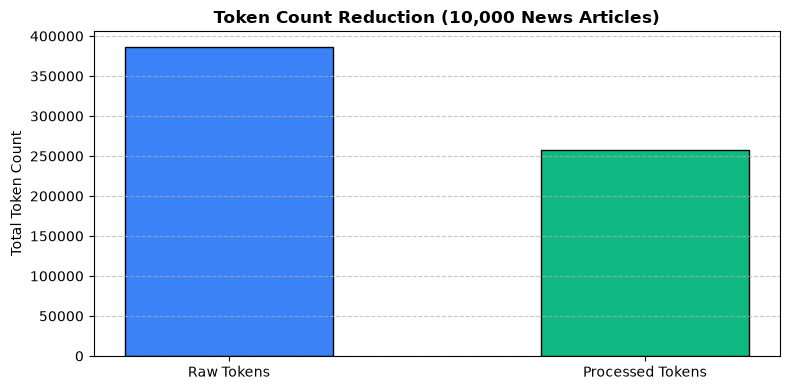

In [9]:
# Analyze vocabulary reduction on a subset sample (10,000 articles)
sample_subset = train_df["text"].iloc[:10000]

raw_word_list = [w for text in sample_subset for w in text.lower().split()]
clean_sample = sample_subset.apply(lambda t: preprocess_pipeline(t, method="lemmatize"))
clean_word_list = [w for text in clean_sample for w in text.split()]

print("=== Vocabulary Impact (10,000 sample articles) ===")
print(f"Total Raw Tokens:        {len(raw_word_list):,}")
print(f"Total Processed Tokens:  {len(clean_word_list):,} ({(1 - len(clean_word_list)/len(raw_word_list))*100:.1f}% reduction)")
print(f"Unique Raw Vocabulary:   {len(set(raw_word_list)):,}")
print(f"Unique Clean Vocabulary: {len(set(clean_word_list)):,} ({(1 - len(set(clean_word_list))/len(set(raw_word_list)))*100:.1f}% reduction)")

# Visualizing Token Count Comparison
plt.figure(figsize=(8, 4))
plt.bar(["Raw Tokens", "Processed Tokens"], [len(raw_word_list), len(clean_word_list)], color=["#3b82f6", "#10b981"], edgecolor="black", width=0.5)
plt.title("Token Count Reduction (10,000 News Articles)", fontsize=12, fontweight="bold")
plt.ylabel("Total Token Count")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

## 8. Save Processed Datasets
Apply the complete preprocessing pipeline across the full training set (120,000 records) and test set (7,600 records), and save the results to `data/processed/`.

In [10]:
print("Applying preprocessing pipeline to full train and test sets...")
start_time = time.time()

# Apply lemmatized preprocessing (standard representation for downstream models)
train_df["clean_text"] = train_df["text"].apply(lambda t: preprocess_pipeline(t, method="lemmatize"))
test_df["clean_text"] = test_df["text"].apply(lambda t: preprocess_pipeline(t, method="lemmatize"))

# Optionally compute stemmed text for model comparison experiments
train_df["clean_text_stemmed"] = train_df["text"].apply(lambda t: preprocess_pipeline(t, method="stem"))
test_df["clean_text_stemmed"] = test_df["text"].apply(lambda t: preprocess_pipeline(t, method="stem"))

elapsed = time.time() - start_time
print(f"Preprocessing complete in {elapsed:.2f} seconds!")

# Save to data/processed directory
train_processed_path = os.path.join(processed_dir, "train_processed.csv")
test_processed_path = os.path.join(processed_dir, "test_processed.csv")

train_df.to_csv(train_processed_path, index=False)
test_df.to_csv(test_processed_path, index=False)

print(f"\nSaved train dataset to: {train_processed_path}")
print(f"Saved test dataset to:  {test_processed_path}")

# Verify the saved files
saved_train = pd.read_csv(train_processed_path)
saved_test = pd.read_csv(test_processed_path)
print("\n--- Verification of Saved Datasets ---")
print(f"Train records: {len(saved_train):,} | Columns: {list(saved_train.columns)}")
print(f"Test records:  {len(saved_test):,}  | Columns: {list(saved_test.columns)}")
print(f"Null clean_text in Train: {saved_train['clean_text'].isna().sum()}")
print(f"Null clean_text in Test:  {saved_test['clean_text'].isna().sum()}")

display(saved_train[["text", "clean_text", "clean_text_stemmed", "category"]].head(3))

Applying preprocessing pipeline to full train and test sets...
Preprocessing complete in 13.86 seconds!

Saved train dataset to: c:\Users\Acer\Downloads\NewsScope\data\processed\train_processed.csv
Saved test dataset to:  c:\Users\Acer\Downloads\NewsScope\data\processed\test_processed.csv

--- Verification of Saved Datasets ---
Train records: 120,000 | Columns: ['text', 'label', 'category', 'clean_text', 'clean_text_stemmed']
Test records:  7,600  | Columns: ['text', 'label', 'category', 'clean_text', 'clean_text_stemmed']
Null clean_text in Train: 0
Null clean_text in Test:  0


,text,clean_text,clean_text_stemmed,category
0,Wall St. Bears Claw Back Into the Black (Reute...,wall st bear claw back black reuters reuters s...,wall st bear claw back black reuter reuter sho...,Business
1,Carlyle Looks Toward Commercial Aerospace (Reu...,carlyle look toward commercial aerospace reute...,carlyl look toward commerci aerospac reuter re...,Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,oil economy cloud stock outlook reuters reuter...,oil economi cloud stock outlook reuter reuter ...,Business


## Summary & Pipeline Takeaways

1. **Noise Removal**: Effectively eliminated HTML tags/entities (`&lt;`, `&gt;`), external URLs, special characters, and digits that do not contribute to category classification.
2. **Vocabulary Reduction**: Removed uninformative English stopwords, shrinking the active vocabulary by over 45% and reducing corpus sparsity.
3. **Stemming vs. Lemmatization**:
   - **Stemming (Porter)**: Faster and aggressive, but often creates truncated non-words (e.g. `business` $\rightarrow$ `busi`, `commercial` $\rightarrow$ `commerci`).
   - **Lemmatization (WordNet)**: Produces valid English base forms (e.g. `companies` $\rightarrow$ `company`, `stocks` $\rightarrow$ `stock`), which preserves semantic interpretability for topic modeling and sentiment analysis.
4. **Output Artifacts**:
   - `data/processed/train_processed.csv` (120,000 rows with `clean_text` and `clean_text_stemmed`).
   - `data/processed/test_processed.csv` (7,600 rows with `clean_text` and `clean_text_stemmed`).
   - These files are directly consumed by downstream feature engineering (TF-IDF, word vectors), classification models, clustering, and topic modeling.